In [2]:
import pandas as pd
import numpy as np

# Load the dataset from the 'data' subfolder
df = pd.read_csv("data/Mall_Customers.csv")

# Display shape and first 5 rows
print("Dataset Shape:", df.shape)
df.head()

Dataset Shape: (200, 5)


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


# Dataset Verification

In [3]:
# Check data types, non-null counts, and missing values
print("--- Dataset Info ---")
print(df.info())

print("\n--- Missing Values Count ---")
print(df.isnull().sum())

print("\n--- Summary Statistics ---")
display(df.describe())

--- Dataset Info ---
<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 8.9 KB
None

--- Missing Values Count ---
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

--- Summary Statistics ---


,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


# EXPLORATORY DATA ANALYTICS

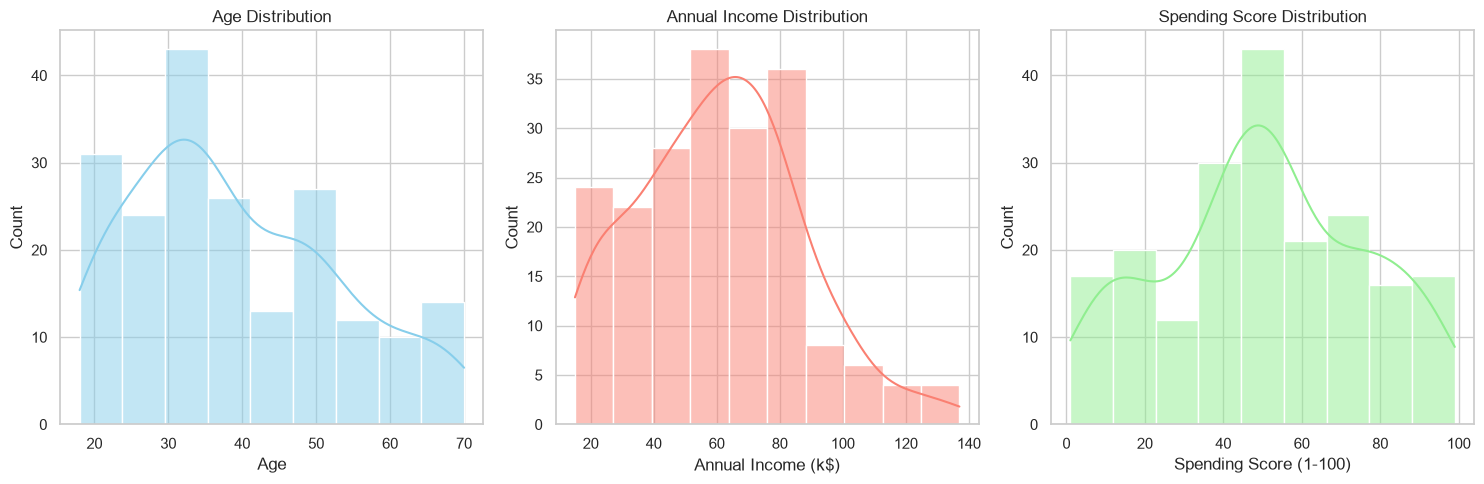

C:\Users\DELL\AppData\Local\Temp\ipykernel_22428\1586115026.py:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Gender', data=df, palette='Set2')


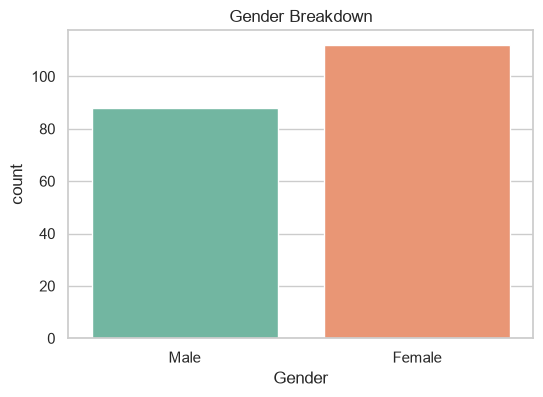

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set style
sns.set_theme(style="whitegrid")

plt.figure(figsize=(15, 5))

# Age distribution
plt.subplot(1, 3, 1)
sns.histplot(df['Age'], kde=True, color='skyblue')
plt.title('Age Distribution')

# Annual Income distribution
plt.subplot(1, 3, 2)
sns.histplot(df['Annual Income (k$)'], kde=True, color='salmon')
plt.title('Annual Income Distribution')

# Spending Score distribution
plt.subplot(1, 3, 3)
sns.histplot(df['Spending Score (1-100)'], kde=True, color='lightgreen')
plt.title('Spending Score Distribution')

plt.tight_layout()
plt.show()

# Gender count plot
plt.figure(figsize=(6, 4))
sns.countplot(x='Gender', data=df, palette='Set2')
plt.title('Gender Breakdown')
plt.show()

# Scatter Plots & Pairwise Relationships

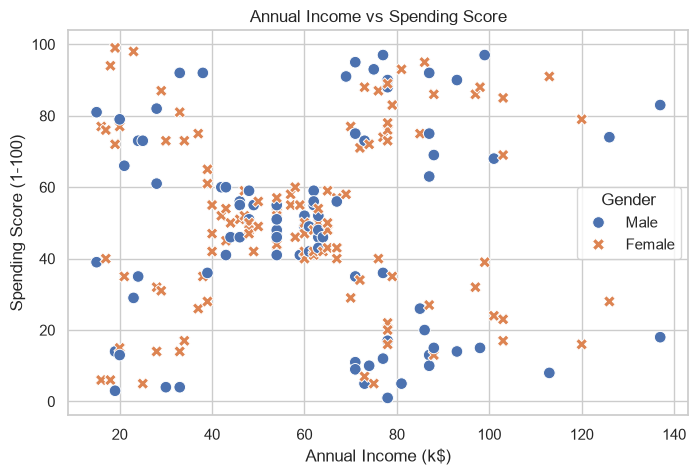

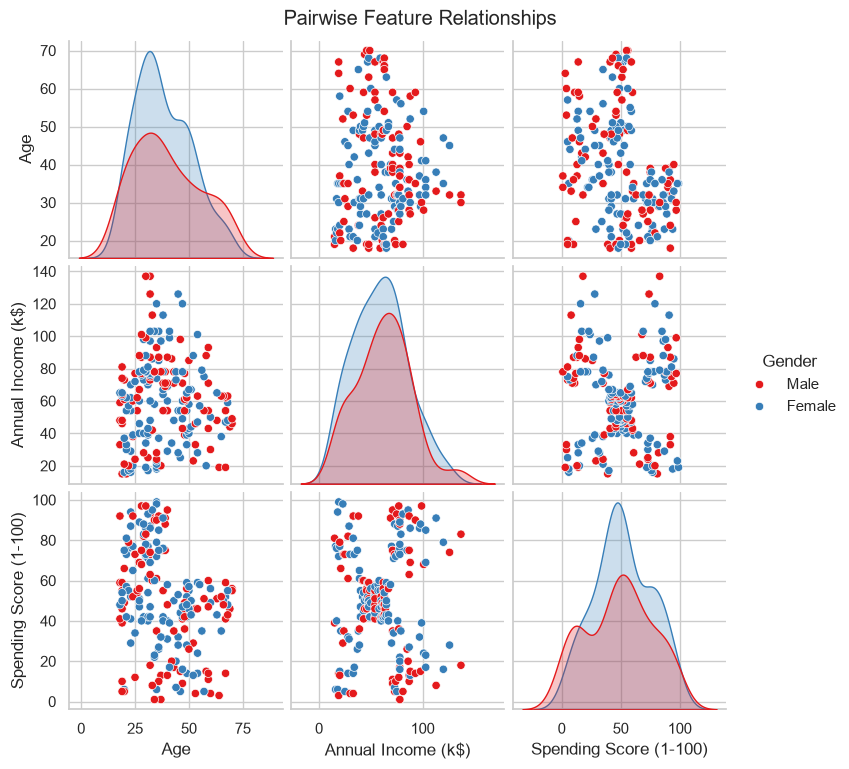

In [6]:
# 1. Scatter Plot: Annual Income vs Spending Score
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df, 
    x='Annual Income (k$)', 
    y='Spending Score (1-100)', 
    hue='Gender', 
    style='Gender', 
    s=70
)
plt.title('Annual Income vs Spending Score')
plt.show()

# 2. Pairplot to view all numerical feature interactions
sns.pairplot(df.drop('CustomerID', axis=1), hue='Gender', palette='Set1')
plt.suptitle('Pairwise Feature Relationships', y=1.02)
plt.show()

# Feature Selection & Standard Scaling

In [7]:
from sklearn.preprocessing import StandardScaler

# Select numerical features for clustering
X = df[['Annual Income (k$)', 'Spending Score (1-100)']]

# Initialize and fit the StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Convert scaled array back to DataFrame for easy viewing
X_scaled_df = pd.DataFrame(X_scaled, columns=X.columns)

print("Original Features (First 3 rows):")
display(X.head(3))

print("\nScaled Features (First 3 rows - Mean ~ 0, Std ~ 1):")
display(X_scaled_df.head(3))

Original Features (First 3 rows):


,Annual Income (k$),Spending Score (1-100)
0,15,39
1,15,81
2,16,6



Scaled Features (First 3 rows - Mean ~ 0, Std ~ 1):


,Annual Income (k$),Spending Score (1-100)
0,-1.738999,-0.434801
1,-1.738999,1.195704
2,-1.700830,-1.715913


# Elbow Method & Silhouette Analysis

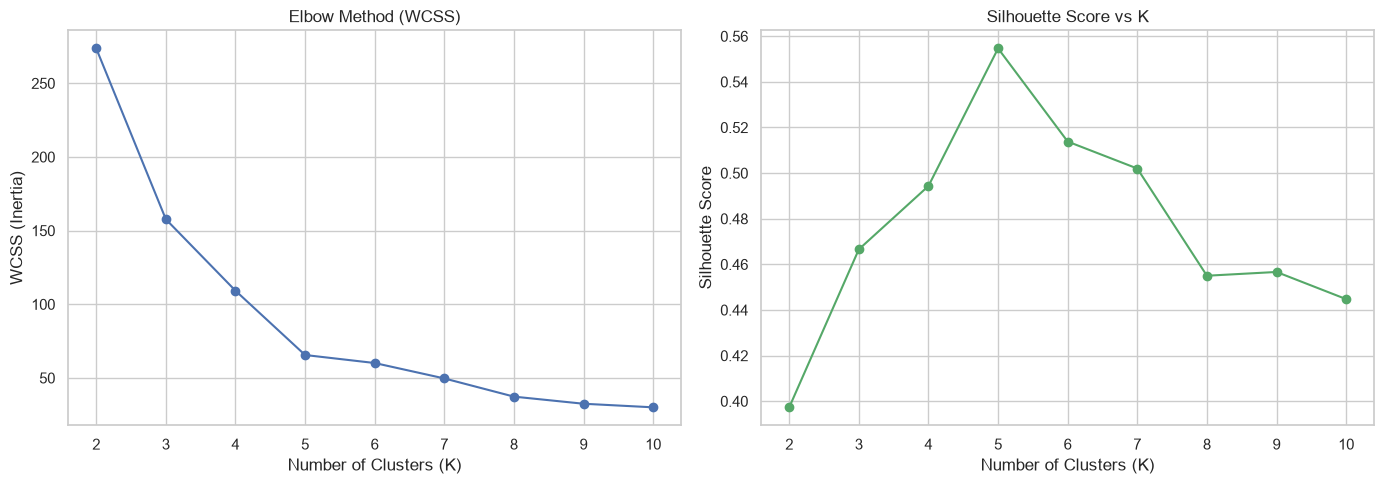

Optimal K based on highest Silhouette Score: 5


In [8]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

wcss = []
silhouette_scores = []
k_range = range(2, 11)

for k in k_range:
    kmeans = KMeans(n_clusters=k, init='k-means++', random_state=42)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)
    
    score = silhouette_score(X_scaled, kmeans.labels_)
    silhouette_scores.append(score)

# Plotting Elbow and Silhouette
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Elbow Method
ax[0].plot(k_range, wcss, marker='o', color='b')
ax[0].set_title('Elbow Method (WCSS)')
ax[0].set_xlabel('Number of Clusters (K)')
ax[0].set_ylabel('WCSS (Inertia)')

# Silhouette Score
ax[1].plot(k_range, silhouette_scores, marker='o', color='g')
ax[1].set_title('Silhouette Score vs K')
ax[1].set_xlabel('Number of Clusters (K)')
ax[1].set_ylabel('Silhouette Score')

plt.tight_layout()
plt.show()

# Print highest silhouette score
best_k = k_range[np.argmax(silhouette_scores)]
print(f"Optimal K based on highest Silhouette Score: {best_k}")

# Final Model Training & Cluster Profiling

In [9]:
from sklearn.metrics import davies_bouldin_score

# 1. Train final model with K=5
kmeans_final = KMeans(n_clusters=5, init='k-means++', random_state=42)
df['Cluster'] = kmeans_final.fit_predict(X_scaled)

# 2. Model Evaluation Metrics
final_silhouette = silhouette_score(X_scaled, df['Cluster'])
final_db_index = davies_bouldin_score(X_scaled, df['Cluster'])

print(f"--- Model Evaluation ---")
print(f"Silhouette Score: {final_silhouette:.4f}")
print(f"Davies-Bouldin Index: {final_db_index:.4f}")

# 3. Cluster Profiling (Mean values per cluster)
print("\n--- Cluster Summary / Profiles ---")
cluster_profile = df.groupby('Cluster').agg({
    'Age': 'mean',
    'Annual Income (k$)': 'mean',
    'Spending Score (1-100)': 'mean',
    'CustomerID': 'count'
}).rename(columns={'CustomerID': 'Customer Count'}).reset_index()

display(cluster_profile)

--- Model Evaluation ---
Silhouette Score: 0.5547
Davies-Bouldin Index: 0.5722

--- Cluster Summary / Profiles ---


,Cluster,Age,Annual Income (k$),Spending Score (1-100),Customer Count
0,0,42.716049,55.296296,49.518519,81
1,1,32.692308,86.538462,82.128205,39
2,2,25.272727,25.727273,79.363636,22
3,3,41.114286,88.200000,17.114286,35
4,4,45.217391,26.304348,20.913043,23


# Segment Naming & Final Cluster Visualization

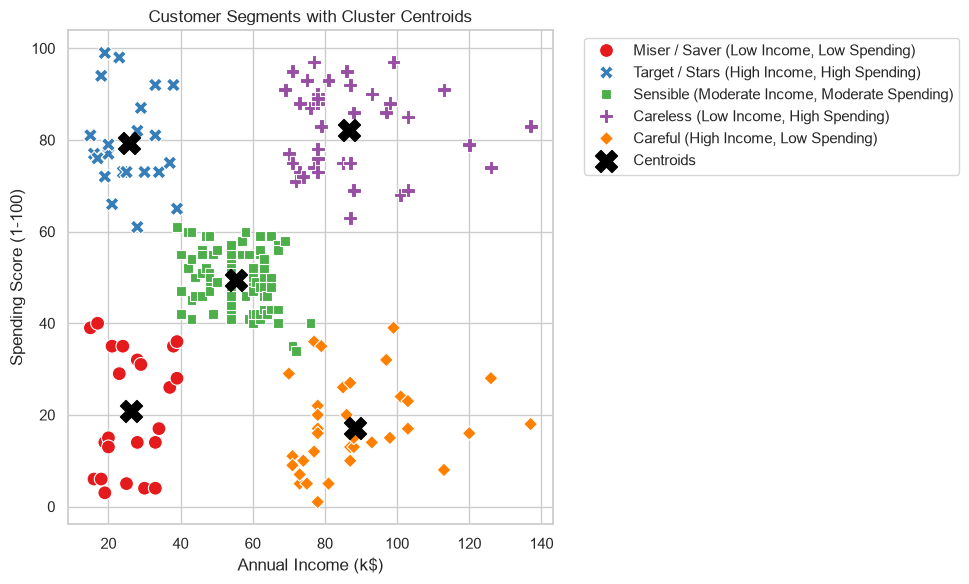

,CustomerID,Annual Income (k$),Spending Score (1-100),Cluster,Segment_Name
0,1,15,39,4,"Miser / Saver (Low Income, Low Spending)"
1,2,15,81,2,"Target / Stars (High Income, High Spending)"
2,3,16,6,4,"Miser / Saver (Low Income, Low Spending)"
3,4,16,77,2,"Target / Stars (High Income, High Spending)"
4,5,17,40,4,"Miser / Saver (Low Income, Low Spending)"


In [10]:
# Map business labels based on Income & Spending profiles
segment_labels = {
    0: 'Sensible (Moderate Income, Moderate Spending)',
    1: 'Careless (Low Income, High Spending)',
    2: 'Target / Stars (High Income, High Spending)',
    3: 'Careful (High Income, Low Spending)',
    4: 'Miser / Saver (Low Income, Low Spending)'
}

# Add label column
df['Segment_Name'] = df['Cluster'].map(segment_labels)

# Plotting final labeled clusters
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df, 
    x='Annual Income (k$)', 
    y='Spending Score (1-100)', 
    hue='Segment_Name', 
    style='Segment_Name',
    palette='Set1', 
    s=100
)

# Plot cluster centers (re-scaled to original values)
centers_original = scaler.inverse_transform(kmeans_final.cluster_centers_)
plt.scatter(
    centers_original[:, 0], 
    centers_original[:, 1], 
    s=250, 
    c='black', 
    marker='X', 
    label='Centroids'
)

plt.title('Customer Segments with Cluster Centroids')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

# Display updated dataframe sample
display(df[['CustomerID', 'Annual Income (k$)', 'Spending Score (1-100)', 'Cluster', 'Segment_Name']].head())

# Serialize the Model & Scaler to Disk

In [11]:
import joblib
import os

# Create a directory to store models if it doesn't exist
os.makedirs("models", exist_ok=True)

# Save the scaler and the trained KMeans model
joblib.dump(scaler, "models/scaler.pkl")
joblib.dump(kmeans_final, "models/kmeans_model.pkl")

print("Model and Scaler successfully saved in 'models/' directory!")
print("Files created:")
print("- models/scaler.pkl")
print("- models/kmeans_model.pkl")

Model and Scaler successfully saved in 'models/' directory!
Files created:
- models/scaler.pkl
- models/kmeans_model.pkl
